# 04 · Cleaning an RO train

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EngMtaleb/chemai/blob/main/projects/p05_when_to_stop/notebooks/04_cleaning_an_ro_train.ipynb)

**Project 5 — When to stop**, at the scale of weeks. A seawater RO train fouls; to hold its production
it needs more net driving pressure, and its feed-channel pressure drop rises — every cubic metre costs
a little more energy than the last. A cleaning (CIP) resets that, at a fixed cost. The rule of the
batch notebooks, unchanged: **clean when the live cost of the next m³ reaches the average cost of the
cycle so far, cleaning included.**

The question asked of the plant record: *if energy were the only reason to clean, when would the
cleanings fall — and when did the operators clean?* Four predictions were written down before any
slope or cost was computed (`DECLARED_BEFORE_RUN_D.md`).

**Data:** the RO plant deposit of Project 3 — Su, Meng & Chang (2026), Membranes 16(8) 257;
[doi:10.5281/zenodo.21055948](https://doi.org/10.5281/zenodo.21055948), CC BY 4.0. Three trains, two
years of daily indicators, 18 cleaning campaigns. The plant is not named by the authors, nor here.

Script version: `step4_ro_cip_economics.py` · record: `VALIDATION.md`, section 6.

In [1]:
# Setup. In Google Colab this clones the repository and installs the package (about a minute).
# On your own machine, run from a clone after:  pip install -e ".[viz,data]"
import os, subprocess, sys
from pathlib import Path
REF = "main"        # before the Project 5 pull request is merged, use "p05-when-to-stop"
if "google.colab" in sys.modules:
    if not Path("/content/chemai").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--branch", REF,
                        "https://github.com/EngMtaleb/chemai.git", "/content/chemai"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "/content/chemai[viz,data]"], check=True)
    sys.path.insert(0, "/content/chemai")
    ROOT = Path("/content/chemai")
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
P5 = ROOT / "projects" / "p05_when_to_stop"
RES = P5 / "results"
sys.path.insert(0, str(P5))          # the step scripts, for the helpers they define

import json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
INK, MUTED, BLUE, ORANGE, GREEN, RED, TEAL = "#1f2933", "#7b8794", "#2f6fb2", "#d9822b", "#3f8f5a", "#c23b3b", "#0f7c8c"

def load(name):
    """A committed result file from projects/p05_when_to_stop/results/."""
    return json.loads((RES / name).read_text())

from chemai.data.ro_deposit import download_deposit, load_daily, load_ledger
download_deposit()            # a few hundred kB from Zenodo, md5-checked (once)
daily, ledger = load_daily(), load_ledger()
print(len(daily), "train-days;", len(ledger), "cleaning campaigns")

1340 train-days; 18 cleaning campaigns


## 1. The live cost of fouling

Per m³ of permeate, a fouled train spends extra energy in proportion to the extra feed pressure:

$$m(t) = \text{price} \times \text{kWh per bar} \times \left(NDP_0 \cdot ndp\_pct(t) + \tfrac12 DP_0 \cdot \Delta dp\_pct(t)\right)$$

`ndp_pct` is the rise of the net driving pressure since the last cleaning (it resets at each one);
`dp_pct` is the pressure drop against a fixed baseline, so its rise since the cycle began is used.
With an energy-recovery device each extra bar costs about 0.037 kWh/m³:

kWh/m3 per bar: 0.0368 with energy recovery, 0.0772 without


15 complete cycles; mid case: {'price': 0.1, 'ndp0': 20.0, 'dp0': 2.0, 'erd': True, 'F': 1.0}


Text(0.0, 1.0, 'the energy penalty of fouling in 15 cycles (mid case)')

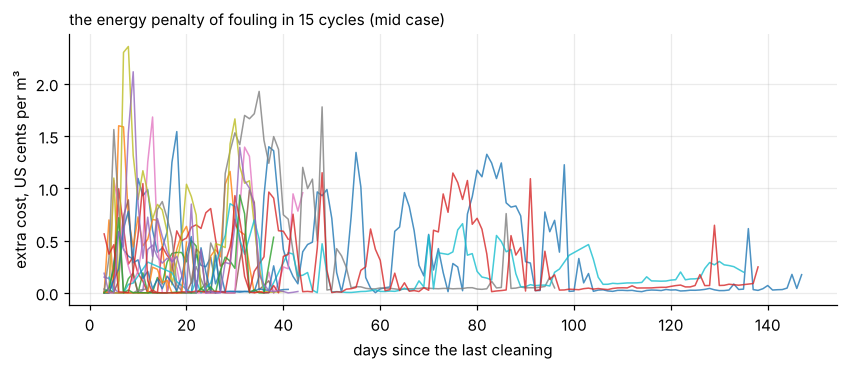

In [2]:
from chemai.features.ro_physics import fouling_energy_penalty, specific_energy_per_bar
print(f"kWh/m3 per bar: {specific_energy_per_bar():.4f} with energy recovery, "
      f"{specific_energy_per_bar(erd_eff=0):.4f} without")
from step4_ro_cip_economics import MID, CORNER, cycle_inputs, judge
cycles = cycle_inputs(daily)
print(len(cycles), "complete cycles;", "mid case:", MID)
fig, ax = plt.subplots(figsize=(9, 3.2))
for c in cycles:
    m = MID["price"] * fouling_energy_penalty(c["ndp"], c["d_dp"], MID["ndp0"], MID["dp0"], specific_energy_per_bar())
    ax.plot(c["day"], m * 100, lw=1, alpha=0.8)
ax.set_xlabel("days since the last cleaning"); ax.set_ylabel("extra cost, US cents per m³")
ax.set_title("the energy penalty of fouling in 15 cycles (mid case)", loc="left", fontsize=10)

Most cycles stay below a third of a cent per m³; many hardly move. A cleaning in the mid case costs
$1 per m³/day of the train's capacity — as much as 100 days of a full cent per m³.

## 2. The rule and the law, cycle by cycle

In [3]:
mid = judge(cycles, MID)
mid["T*/T"] = (mid.t_star_d / mid.length_d).round(1)
mid[["id", "length_d", "slope_usd_m3_d", "t_star_d", "T*/T", "rule_day", "implied_F", "penalty_end_usd_m3"]].round(5)

,id,length_d,slope_usd_m3_d,t_star_d,T*/T,rule_day,implied_F,penalty_end_usd_m3
0,A:579-727,148.0,-0.00002,inf,inf,None,-0.22319,0.00042
1,A:727-765,38.0,-0.00011,inf,inf,None,-0.07467,0.00013
2,B:456-482,26.0,0.00016,112.14117,4.3,None,0.04970,0.00298
3,B:482-524,42.0,0.00010,138.27815,3.3,None,0.08791,0.00589
4,B:526-544,18.0,0.00014,120.09755,6.7,None,0.02004,0.00331
5,B:545-584,39.0,0.00000,inf,inf,None,0.00000,0.00116
6,B:584-629,45.0,0.00000,inf,inf,None,0.00000,0.00248
7,B:629-726,97.0,-0.00001,inf,inf,None,-0.04452,0.00049
8,B:726-767,41.0,-0.00024,inf,inf,None,-0.18875,0.00011
9,C:345-481,136.0,0.00001,437.96781,3.2,None,0.09501,0.00262


In the mid case the rule never reaches its stop before the operators cleaned: **0 of 15** (declared:
at most 4). In nine cycles the penalty did not rise at all (`t_star_d` is infinite); in the other six,
energy alone would have waited 3 to 110 times longer. The *implied* cost — what a cleaning would have
to cost for the interval the operators chose to be the energy-optimal one — has a median of zero.

## 3. Every price and plant assumption at once

In [4]:
grid = pd.read_csv(RES / "step4_grid.csv")
print(grid.rule_before_operators.value_counts().sort_index().rename("cases").to_frame().T)
corner = judge(cycles, CORNER)
print("corner most in favour of cleaning:", CORNER, "->", int(corner.rule_before_operators.sum()), "of 15")

rule_before_operators    0   2   3  4  6
cases                  156  24  29  4  3
corner most in favour of cleaning: {'price': 0.15, 'ndp0': 25.0, 'dp0': 3.0, 'erd': False, 'F': 0.5} -> 6 of 15


In 156 of the 216 combinations energy paid for none of the cleanings; at most 6 of 15 in the corner
most in favour of cleaning ($0.15/kWh, no energy recovery, a cleaning at $0.50 per m³/day).

## 4. The cost of waiting that energy does not see

Text(0.0, 1.0, 'Spearman 0.628, p = 0.016, 14 cycles')

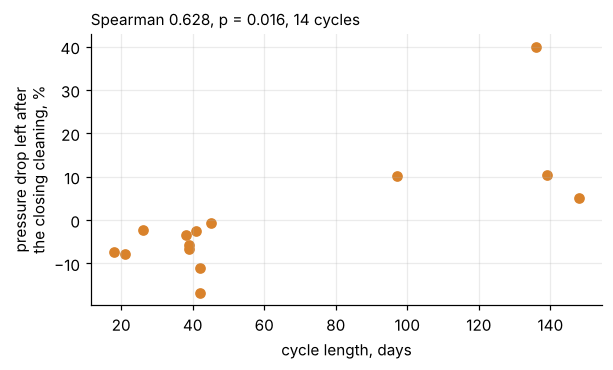

In [5]:
d4 = load("step4_ro_cip_economics.json")["D4"]
from chemai.data.ro_deposit import recovery_by_campaign
rec = recovery_by_campaign(daily, ledger)
xs, ys = [], []
for c in cycles:
    train, end = c["train"], int(c["id"].split(":")[1].split("-")[1])
    r = rec[(rec.train == train) & (rec.day >= end) & (rec.day <= end + 7) & rec.evaluable]
    if len(r):
        xs.append(c["length"]); ys.append(float(r.post.iloc[-1]) - c["dp_start"])
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.scatter(xs, np.array(ys) * 100, color=ORANGE)
ax.set_xlabel("cycle length, days"); ax.set_ylabel("pressure drop left after\nthe closing cleaning, %")
ax.set_title(f"Spearman {d4['spearman_rho']}, p = {d4['p']}, {d4['cycles']} cycles", loc="left", fontsize=10)

Longer cycles left more pressure drop behind after their cleaning — fouling that hardens with time.
It rests on four long cycles against ten short ones on one plant: a reason to look, not a price.

**What it means.** Energy is the smallest reason to clean an RO train. A schedule defended by energy
savings is defended by the weakest of its arguments; the pressure-drop limit that protects the
elements, salt passage, and fouling that hardens are the real ones — and the first of them is what
Project 3 forecasts.